# Pergunta 1.2: quais atributos do criativo se associam a boa performance?

> **Pergunta do case:** quais atributos do criativo mais se correlacionam com boas métricas de performance (CTR, ROAS, conversões etc.)?

| Passo | Pergunta | Ferramenta |
|---|---|---|
| 1 | O que sei antes de postar e o que só sei depois? | separar as colunas em três grupos |
| 2 | Quais atributos andam junto com quais métricas? | correlação de Pearson e de Spearman |
| 3 | Quanto cada atributo sim/não muda cada métrica? | diferença das medianas, com intervalo de 95% |
| 4 | E formato e quantidade de texto? | medianas por grupo, boxplot e eta² |
| 5 | E duração e música/voz? | dispersão e mediana por faixa |
| 6 | O efeito é do criativo ou do público? | comparar dentro de grupos e regressão linear |
| 7 | O efeito muda com o público? | diferença dentro de cada idade e objetivo |
| 8 | Mantendo o resto igual, o criativo mexe em quais métricas? | regressão no log de cada métrica |
| 9 | A "boa métrica" muda com o objetivo? | efeito na métrica principal de cada objetivo |

Uma nota sobre as métricas: a pergunta cita CTR, ROAS e conversões "etc.". Analiso **nove**: CTR, engajamento, retenção, taxa de conversão, conversões, ROAS, CPC, CPA e a nota `klike_score`. A nota é o alvo da Parte 2; as outras mostram **em que etapa do funil** cada atributo age.

Toda a análise usa só o **treino** (o teste continua guardado). A explicação de cada decisão está em `docs/parte1/1_2_atributos_x_performance.md`.

## Passo 0: preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

RAIZ = Path("../..")  # o notebook fica em notebooks/parte1
sys.path.append(str(RAIZ))
from src.limpeza import carregar, limpar, separar_treino_teste

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
AZUL, CINZA, CINZA_CLARO = "#2a78d6", "#52514e", "#b8b7b1"


def estilo_limpo(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)

In [2]:
# Mesma divisão e mesma limpeza do notebook 1.1 (passo a passo explicado lá)
treino_bruto, teste_bruto = separar_treino_teste(carregar(RAIZ / "data/raw/klike_challenge_dataset.csv"))
treino = limpar(treino_bruto)
print(treino.shape)

(400, 37)


## Passo 1: o que sei antes de postar e o que só sei depois?

| Grupo | Colunas | Quando eu sei |
|---|---|---|
| **Atributos do criativo** (o que o time controla) | gancho (`has_hook`), rosto (`has_face`), chamada para ação (`has_cta`), legenda (`has_subtitle`), formato, densidade de texto, duração, música/voz | **antes** de postar |
| **Contexto da campanha** | plataforma, categoria, objetivo, idade do público, retargeting | **antes** de postar (mas não é o vídeo) |
| **Resultado** | CTR, engajamento, retenção, taxa de conversão, conversões, ROAS, CPC, CPA e a nota `klike_score` | só **depois** que o vídeo roda |

A Klike promete dar a nota **antes** do vídeo ir ao ar. Por isso, na Parte 2, o modelo não pode usar CTR ou retenção para prever a nota: no momento da previsão, esses números ainda não existem. Seria como corrigir a prova olhando o gabarito. Aqui, os atributos são os candidatos a "causa", as métricas são o resultado, e o contexto pode **confundir** a leitura (passo 6).

**Uso só valores reais.** O notebook 1.1 preencheu alguns vazios com a mediana. Para medir efeitos, volto esses valores a vazio usando o indicador de faltante: valores preenchidos ficam todos iguais à mediana e diluiriam as diferenças que eu quero medir. O ROAS fica vazio para Branding, onde ele não se aplica.

In [3]:
reais = treino.copy()
for coluna in ["video_duration_s", "music_voice_ratio", "avg_watch_time_s", "engagement_rate"]:
    reais.loc[reais[f"{coluna}_faltava"] == 1, coluna] = np.nan
# A retenção só é real se a duração e o tempo assistido eram reais
reais["retencao"] = reais["avg_watch_time_s"] / reais["video_duration_s"]
reais.loc[reais["category"] == "Branding", "roas"] = np.nan

METRICAS = {"ctr": "CTR", "engagement_rate": "Engajamento", "retencao": "Retenção", "taxa_conversao": "Taxa de conversão",
            "conversions": "Conversões", "roas": "ROAS (sem Branding)", "cpc": "CPC (menor é melhor)", "cpa": "CPA (menor é melhor)",
            "klike_score": "klike_score"}
reais[list(METRICAS)].notna().sum().rename("criativos com valor real").to_frame().T

,ctr,engagement_rate,retencao,taxa_conversao,conversions,roas,cpc,cpa,klike_score
criativos com valor real,400,373,351,400,400,351,400,384,400


## Passo 2: quais atributos andam junto com quais métricas?

A **correlação de Pearson** vai de −1 a +1 e mede o quanto duas colunas andam juntas **em linha reta**; perto de 0 = sem relação em linha reta. A **correlação de Spearman** é a mesma conta feita sobre a *ordem* dos valores (1º, 2º, 3º...): mede se "quando um sobe, o outro sobe", em reta ou em curva, e não se deixa levar por um valor gigante. Calculo as duas: se Spearman for bem maior que Pearson, a relação é forte, mas curva.

Atributos sim/não viram 1 e 0 (sim = 1). A densidade de texto vira 0, 1 e 2 (pouco, médio, muito).

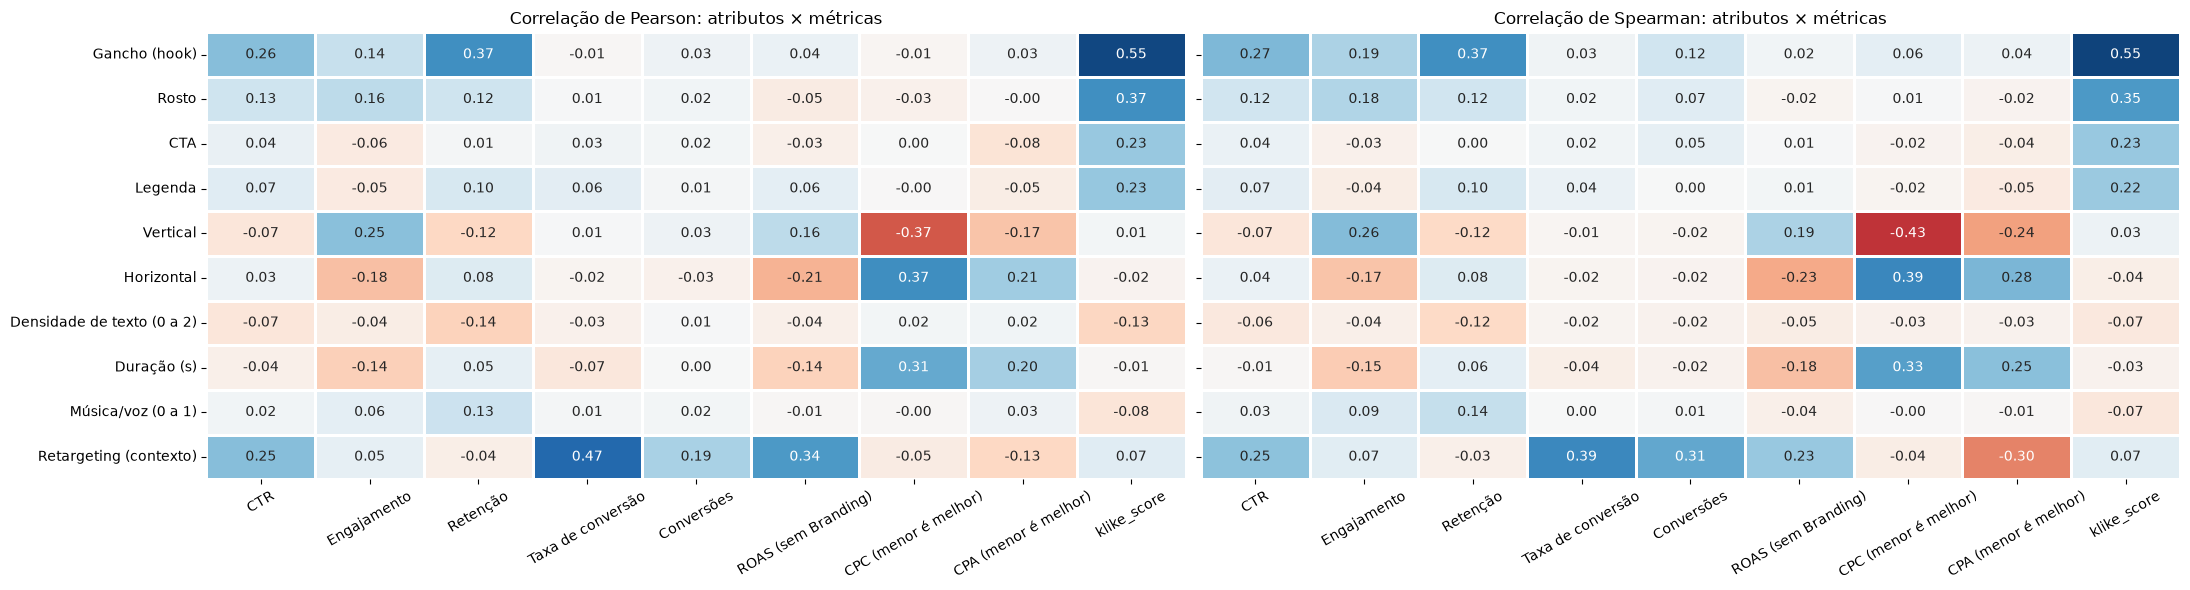

In [4]:
atributos = pd.DataFrame({
    "Gancho (hook)": reais["has_hook"].astype(int),
    "Rosto": reais["has_face"].astype(int),
    "CTA": reais["has_cta"].astype(int),
    "Legenda": reais["has_subtitle"].map({"sim": 1, "nao": 0}),  # "desconhecido" fica vazio
    "Vertical": (reais["format"] == "vertical").astype(int),
    "Horizontal": (reais["format"] == "horizontal").astype(int),
    "Densidade de texto (0 a 2)": reais["text_density"].map({"low": 0, "medium": 1, "high": 2}),
    "Duração (s)": reais["video_duration_s"],
    "Música/voz (0 a 1)": reais["music_voice_ratio"],
    "Retargeting (contexto)": reais["is_retargeting"].astype(int),
})
pearson = pd.DataFrame({nome: atributos.corrwith(reais[metrica]) for metrica, nome in METRICAS.items()})
spearman = pd.DataFrame({nome: atributos.corrwith(reais[metrica], method="spearman") for metrica, nome in METRICAS.items()})

fig, eixos = plt.subplots(1, 2, figsize=(22, 6), sharey=True)
for ax, (tabela, titulo) in zip(eixos, [(pearson, "Pearson"), (spearman, "Spearman")]):
    sns.heatmap(tabela, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-0.6, vmax=0.6, cbar=False, ax=ax,
                linewidths=2, linecolor="white")
    ax.set_title(f"Correlação de {titulo}: atributos × métricas")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

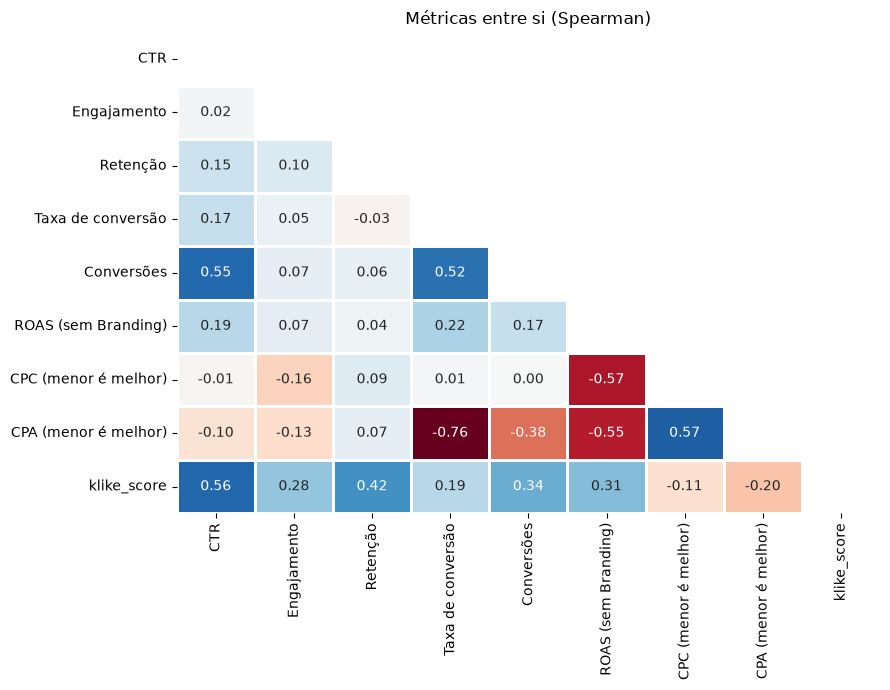

In [5]:
# As métricas entre si: o que a nota klike_score acompanha?
metricas_entre_si = reais[list(METRICAS)].rename(columns=METRICAS).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(metricas_entre_si, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-0.7, vmax=0.7, cbar=False, ax=ax,
            mask=np.triu(np.ones_like(metricas_entre_si, dtype=bool)), linewidths=2, linecolor="white")
ax.set_title("Métricas entre si (Spearman)")
plt.tight_layout()
plt.show()

In [6]:
# Atributos que repetem informação: pares com correlação acima de 0,6 
entre_atributos = atributos.drop(columns=["Vertical", "Horizontal", "Retargeting (contexto)"]).corr()
acima_da_diagonal = np.triu(np.ones(entre_atributos.shape, dtype=bool), k=1)
pares = entre_atributos.where(acima_da_diagonal).stack()
print(f"Maior correlação entre dois atributos do criativo: {pares.abs().max():.2f} ({' × '.join(pares.abs().idxmax())})")

Maior correlação entre dois atributos do criativo: 0.11 (Gancho (hook) × Legenda)


**Lendo os mapas:**

- **Na nota, o gancho é o atributo mais ligado** (Spearman de cerca de +0,55), seguido de rosto, CTA e legenda (entre +0,2 e +0,35). No CTR, gancho e rosto são os únicos com correlação clara.
- **A densidade de texto tem correlação perto de zero com a nota, mas importa muito** (passo 4): o melhor é o nível médio, e os dois extremos perdem. A correlação mede relação em linha reta (ou sempre subindo), e esta relação tem forma de morro. **Correlação perto de 0 não quer dizer que não há relação.**
- Pearson e Spearman quase coincidem: as relações dos atributos com as métricas são simples, sem curvas escondidas.
- **A nota acompanha o CTR (0,56) e a retenção (cerca de 0,4).** Faz sentido, mas na Parte 2 essas métricas não podem entrar como colunas do modelo: elas só existem depois de postar.
- **Os atributos do criativo não repetem informação entre si** (maior correlação entre dois deles: 0,11). Cada um traz algo próprio.

## Passo 3: quanto cada atributo sim/não muda cada métrica?

Para cada atributo, separo os criativos **com** e **sem** ele e comparo a **mediana** de cada métrica (a mediana porque as métricas têm cauda longa; ver notebook 1.1). O resultado é a **diferença em %**: `mediana com ÷ mediana sem − 1`. Mostro sempre o **n** (número de criativos) de cada grupo.

**Quanto confiar nessa diferença?** Com 400 criativos, outra amostra daria um número um pouco diferente. Para medir o quanto, uso o **bootstrap**: sorteio 2.000 vezes, com reposição, um grupo "com" e um grupo "sem" do mesmo tamanho dos reais e recalculo a diferença. Os 95% do meio desses sorteios formam o **intervalo de 95%**. Se o intervalo inteiro fica acima (ou abaixo) de zero, chamo o efeito de **confiável**: mesmo variando a amostra, ele não some.

Cuidado com **muitas comparações**: são 5 atributos × 9 métricas = 45 diferenças. Mesmo sem efeito real, algumas pareceriam confiáveis por sorte (cerca de 2 em 45). Por isso só destaco efeitos que também se repetem em outras métricas ou plataformas.

In [7]:
def comparar(com, sem, sorteios=2000):
    """Diferença % das medianas (com ÷ sem − 1) e o intervalo de 95% por bootstrap."""
    com, sem = com.dropna().to_numpy(), sem.dropna().to_numpy()
    gerador = np.random.default_rng(42)
    # Cada linha da matriz é um sorteio com reposição, do mesmo tamanho do grupo real
    medianas_com = np.median(com[gerador.integers(0, len(com), (sorteios, len(com)))], axis=1)
    medianas_sem = np.median(sem[gerador.integers(0, len(sem), (sorteios, len(sem)))], axis=1)
    baixo, alto = np.percentile((medianas_com / medianas_sem - 1) * 100, [2.5, 97.5])
    return {"n com": len(com), "n sem": len(sem), "mediana com": np.median(com), "mediana sem": np.median(sem),
            "diferença (%)": (np.median(com) / np.median(sem) - 1) * 100,
            "intervalo baixo (%)": baixo, "intervalo alto (%)": alto, "confiável?": baixo > 0 or alto < 0}


ATRIBUTOS_SIM_NAO = {"Gancho (hook)": reais["has_hook"], "Rosto": reais["has_face"], "CTA": reais["has_cta"],
                     "Legenda": reais["has_subtitle"].map({"sim": True, "nao": False}),
                     "Retargeting (contexto)": reais["is_retargeting"]}

linhas = []
for atributo, tem in ATRIBUTOS_SIM_NAO.items():
    for metrica, nome in METRICAS.items():
        resultado = comparar(reais.loc[tem == True, metrica], reais.loc[tem == False, metrica])
        linhas.append({"atributo": atributo, "métrica": nome, **resultado})
efeitos = pd.DataFrame(linhas)

# Visão resumida: diferença % e um ✓ quando o intervalo de 95% não cruza o zero
resumo_efeitos = efeitos.assign(célula=efeitos["diferença (%)"].map("{:+.0f}%".format) + np.where(efeitos["confiável?"], " ✓", ""))
resumo_efeitos.pivot(index="atributo", columns="métrica", values="célula")[list(METRICAS.values())]

métrica,CTR,Engajamento,Retenção,Taxa de conversão,Conversões,ROAS (sem Branding),CPC (menor é melhor),CPA (menor é melhor),klike_score
atributo,,,,,,,,,
CTA,-3%,+5%,-1%,+2%,+24%,+15%,-4%,-5%,+12% ✓
Gancho (hook),+66% ✓,+56% ✓,+42% ✓,+4%,+46%,-4%,+4%,+8%,+34% ✓
Legenda,+15%,-6%,+9%,+3%,+19%,+15%,+0%,-5%,+11% ✓
Retargeting (contexto),+70% ✓,+15%,+2%,+89% ✓,+273% ✓,+66% ✓,-4%,-44% ✓,+1%
Rosto,+35% ✓,+51% ✓,+17% ✓,+9%,+41%,+6%,+1%,-1%,+19% ✓


In [8]:
# A tabela completa, com o n e o intervalo de cada comparação
efeitos.round(3)

,atributo,métrica,n com,n sem,mediana com,mediana sem,diferença (%),intervalo baixo (%),intervalo alto (%),confiável?
0,Gancho (hook),CTR,206,194,0.078,0.047,65.820,31.805,102.501,True
1,Gancho (hook),Engajamento,195,178,0.025,0.016,56.329,17.615,86.303,True
2,Gancho (hook),Retenção,181,170,0.625,0.441,41.586,26.481,60.151,True
3,Gancho (hook),Taxa de conversão,206,194,0.033,0.031,4.465,-15.035,24.975,False
4,Gancho (hook),Conversões,206,194,43.000,29.500,45.763,-4.289,122.465,False
5,Gancho (hook),ROAS (sem Branding),183,168,1.840,1.910,-3.665,-24.887,34.995,False
6,Gancho (hook),CPC (menor é melhor),206,194,0.725,0.700,3.571,-4.227,24.603,False
7,Gancho (hook),CPA (menor é melhor),202,182,25.258,23.418,7.858,-9.787,41.126,False
8,Gancho (hook),klike_score,206,194,69.850,52.250,33.684,26.914,40.058,True
9,Rosto,CTR,213,187,0.071,0.052,35.238,4.851,66.333,True


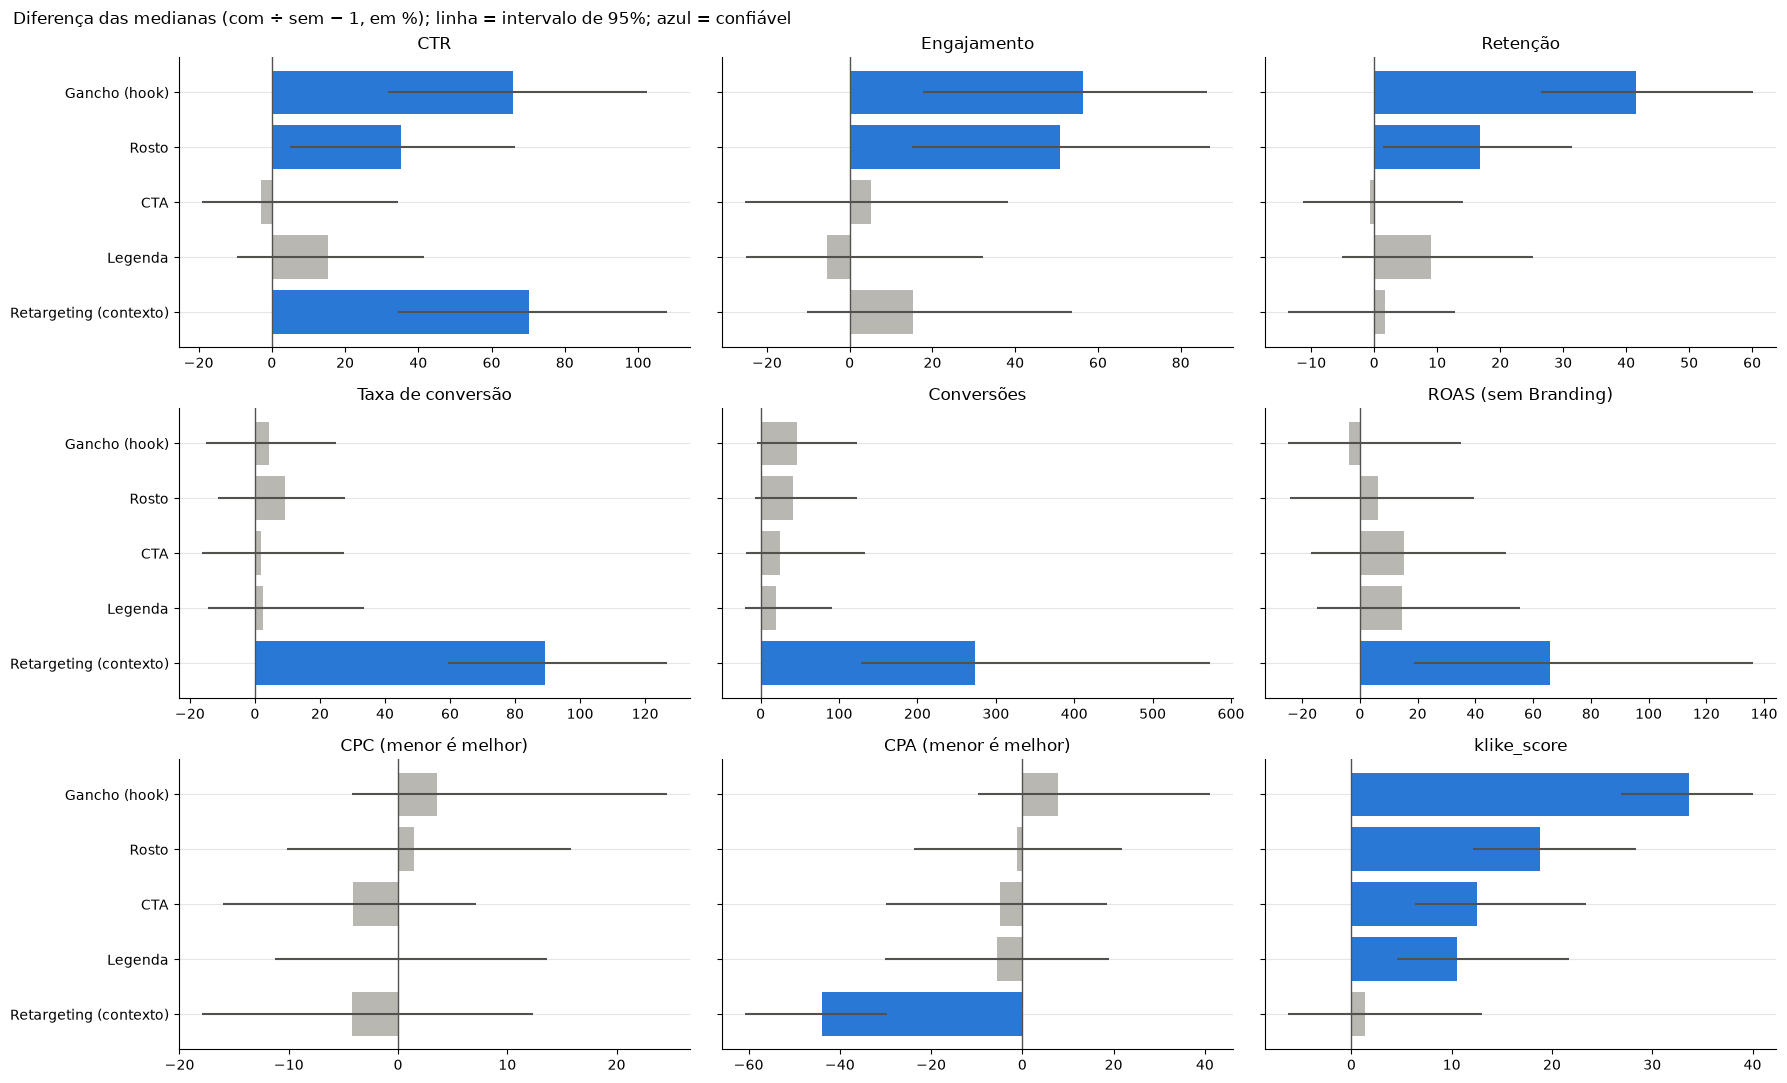

In [9]:
fig, eixos = plt.subplots(3, 3, figsize=(18, 11), sharey=True)
for ax, nome in zip(eixos.flat, METRICAS.values()):
    parte = efeitos[efeitos["métrica"] == nome].iloc[::-1]
    cores = np.where(parte["confiável?"], AZUL, CINZA_CLARO)
    ax.barh(parte["atributo"], parte["diferença (%)"], color=cores)
    ax.hlines(parte["atributo"], parte["intervalo baixo (%)"], parte["intervalo alto (%)"], color=CINZA, linewidth=1.5)
    ax.axvline(0, color=CINZA, linewidth=1)
    ax.set_title(nome, fontsize=12)
    estilo_limpo(ax)
fig.suptitle("Diferença das medianas (com ÷ sem − 1, em %); linha = intervalo de 95%; azul = confiável", x=0.01, ha="left")
plt.tight_layout()
plt.show()

In [10]:
# Na nota, a diferença em pontos é mais fácil de ler que em %
nota = efeitos[efeitos["métrica"] == "klike_score"].set_index("atributo")
(nota["mediana com"] - nota["mediana sem"]).round(1).rename("diferença na nota (pontos)").to_frame()

,diferença na nota (pontos)
atributo,
Gancho (hook),17.6
Rosto,10.5
CTA,7.0
Legenda,6.1
Retargeting (contexto),0.8


**Pelos números:**

- **Gancho é o atributo mais forte:** +66% de CTR (intervalo de +32% a +103%, com 206 criativos com gancho e 194 sem), +56% de engajamento, +42% de retenção e **+17,6 pontos de nota**.
- **Rosto vem em seguida:** +35% de CTR, +51% de engajamento e +10,5 pontos de nota.
- **CTA e legenda mexem só na nota** (+7,0 e +6,1 pontos); no CTR, a diferença não é confiável.
- **Nenhum atributo do criativo muda de forma confiável a taxa de conversão, o ROAS, o CPC ou o CPA.** O criativo atua no começo do funil (chamar atenção, fazer clicar, prender); vender depende mais da oferta e do público.
- **Atenção ao retargeting:** ele não é um atributo do vídeo, é o público, e aparece com +70% de CTR, o mesmo tamanho do gancho. É o primeiro sinal de que o público pode confundir a leitura (passo 6).

## Passo 4: formato e quantidade de texto

Aqui as colunas têm três níveis, então comparo a mediana de cada nível (com o n). Para resumir num número quanto a coluna "explica" a métrica, uso o **eta²**: a fração da variação da métrica que se explica só por saber o grupo (0 = nada, 1 = tudo).

In [11]:
def eta2(valores, grupos):
    """Fração da variação de `valores` explicada só por saber o grupo (0 = nada, 1 = tudo)."""
    tem_valor = valores.notna()
    valores, grupos = valores[tem_valor], grupos[tem_valor]
    media_do_grupo = valores.groupby(grupos).transform("mean")
    return ((media_do_grupo - valores.mean()) ** 2).sum() / ((valores - valores.mean()) ** 2).sum()


ORDEM = {"format": ["vertical", "quadrado", "horizontal"], "text_density": ["low", "medium", "high"]}
for coluna, ordem in ORDEM.items():
    tabela = reais.groupby(coluna)[["ctr", "engagement_rate", "retencao", "klike_score"]].median().loc[ordem]
    tabela.insert(0, "criativos", reais[coluna].value_counts().loc[ordem])
    print(f"\n{coluna}: medianas por nível")
    print(tabela.round(3).to_string())

pd.DataFrame({coluna: {nome: eta2(reais[metrica], reais[coluna]) for metrica, nome in METRICAS.items()}
              for coluna in ORDEM}).T.round(3)


format: medianas por nível
            criativos    ctr  engagement_rate  retencao  klike_score
format                                                              
vertical          218  0.059            0.027     0.500        61.70
quadrado           92  0.069            0.016     0.508        61.35
horizontal         90  0.065            0.016     0.559        58.10

text_density: medianas por nível
              criativos    ctr  engagement_rate  retencao  klike_score
text_density                                                          
low                 151  0.066            0.022     0.533        58.60
medium              180  0.069            0.022     0.545        67.35
high                 69  0.043            0.017     0.445        48.10


,CTR,Engajamento,Retenção,Taxa de conversão,Conversões,ROAS (sem Branding),CPC (menor é melhor),CPA (menor é melhor),klike_score
format,0.005,0.065,0.015,0.000,0.001,0.044,0.176,0.049,0.000
text_density,0.020,0.003,0.043,0.013,0.000,0.007,0.009,0.006,0.168


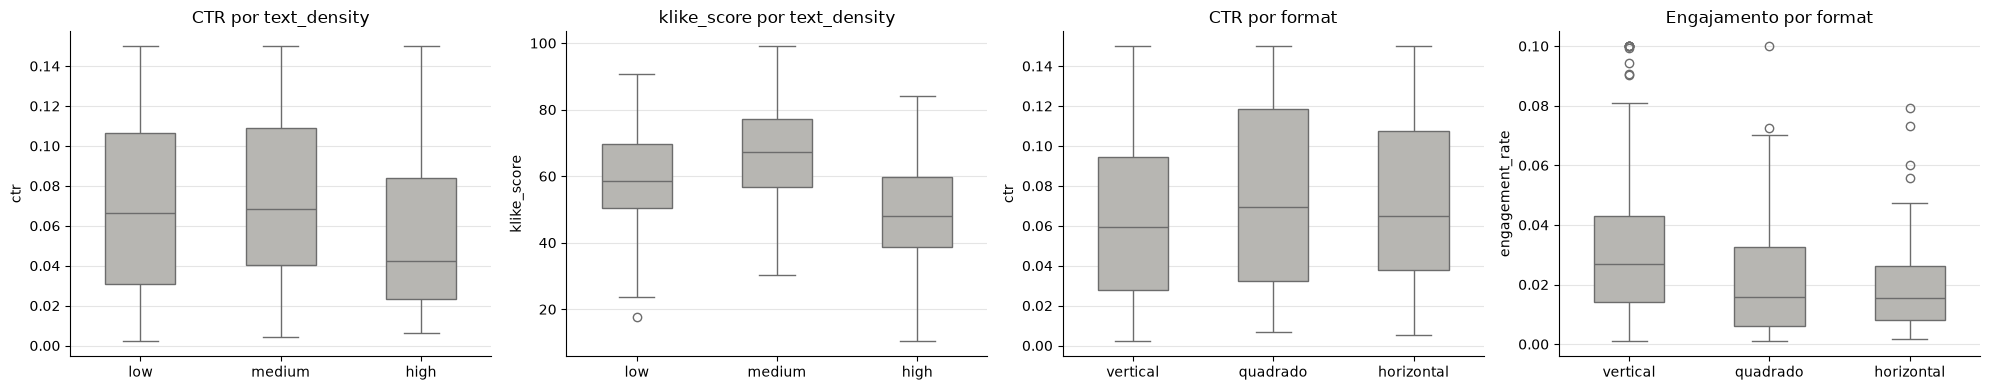

In [12]:
fig, eixos = plt.subplots(1, 4, figsize=(20, 4))
for ax, (coluna, metrica) in zip(eixos, [("text_density", "ctr"), ("text_density", "klike_score"),
                                         ("format", "ctr"), ("format", "engagement_rate")]):
    sns.boxplot(data=reais, x=coluna, y=metrica, order=ORDEM[coluna], color=CINZA_CLARO, width=0.5, ax=ax)
    ax.set_title(f"{METRICAS[metrica]} por {coluna}", fontsize=12)
    ax.set_xlabel("")
    estilo_limpo(ax)
plt.tight_layout()
plt.show()

O **boxplot** resume cada grupo em cinco números: a caixa vai do 1º ao 3º quartil (os 50% do meio), a linha dentro é a mediana, e os pontinhos são valores extremos.

**Lendo as medianas, o eta² e os boxplots:**

- **Muito texto derruba o resultado:** CTR mediano de 0,043 com muito texto contra 0,069 com texto médio; nota de 48,1 contra 67,4. **Pouco texto também perde para o médio** na nota (58,6). O ponto ótimo está no meio. A densidade de texto explica 17% da variação da nota (eta² 0,17).
- **O formato quase não muda o CTR nem a nota** (eta² 0,005 e 0,000). Ele parece mudar o CPC (eta² 0,18) e o engajamento (0,065), mas isso é efeito da plataforma: o TikTok é quase só vertical e tem CPC baixo e engajamento alto. Formato e plataforma andam juntos (V de Cramér de 0,39 no notebook 1.1), então a diferença de formato é, em boa parte, diferença de plataforma. Separo as duas no passo 6 e no notebook 1.3.

## Passo 5: duração e música/voz

Gráfico de dispersão (cada ponto é um criativo) com a **mediana por faixa** por cima: divido a coluna em faixas e marco a mediana da métrica em cada uma. Se existir uma "duração ideal", a linha sobe e depois desce. Para a música/voz uso 5 faixas com o mesmo número de criativos (`pd.qcut`).

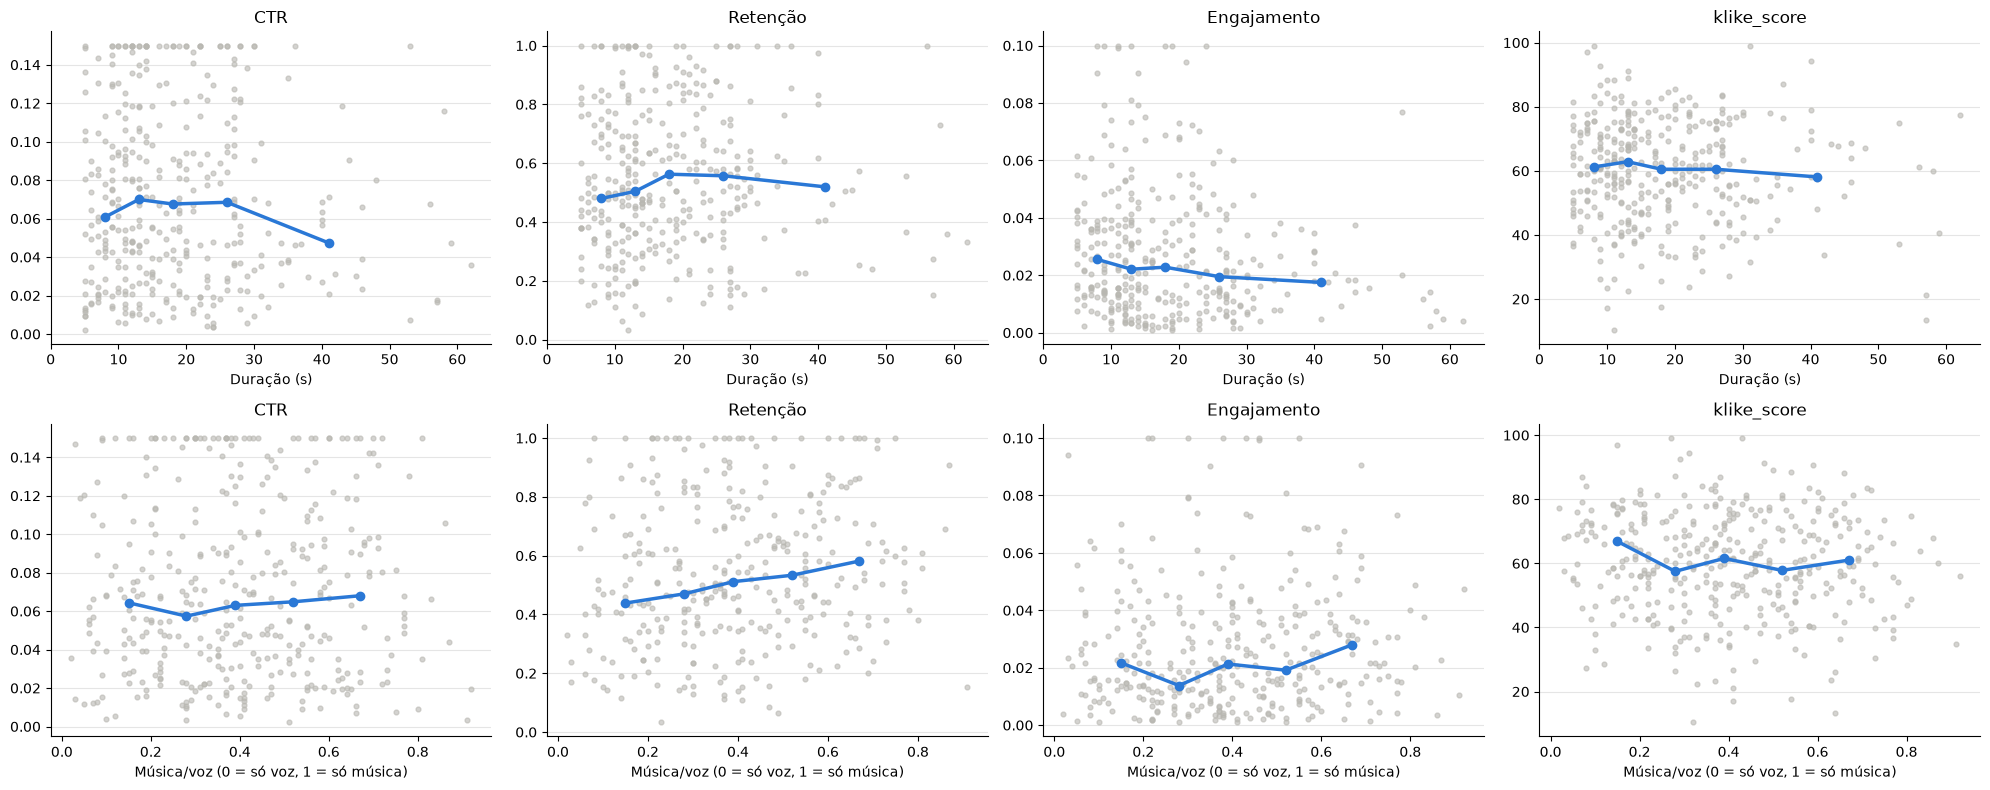

In [13]:
reais["faixa_musica"] = pd.qcut(reais["music_voice_ratio"], 5)
metricas_continuas = ["ctr", "retencao", "engagement_rate", "klike_score"]

fig, eixos = plt.subplots(2, 4, figsize=(20, 8))
for linha, (coluna, faixa, rotulo) in enumerate([("video_duration_s", "faixa_duracao", "Duração (s)"),
                                                 ("music_voice_ratio", "faixa_musica", "Música/voz (0 = só voz, 1 = só música)")]):
    for ax, metrica in zip(eixos[linha], metricas_continuas):
        ax.scatter(reais[coluna], reais[metrica], s=12, color=CINZA_CLARO, alpha=0.6)
        por_faixa = reais.groupby(faixa, observed=True).agg(x=(coluna, "median"), y=(metrica, "median"))
        ax.plot(por_faixa["x"], por_faixa["y"], marker="o", color=AZUL, linewidth=2.5)
        if coluna == "video_duration_s":
            ax.set_xlim(0, 65)  # poucos vídeos passam de 65 s; o corte é só no gráfico
        ax.set_title(METRICAS[metrica], fontsize=12)
        ax.set_xlabel(rotulo)
        estilo_limpo(ax)
plt.tight_layout()
plt.show()

In [14]:
# Só com durações reais (as preenchidas ficam de fora)
duracao_real = reais["video_duration_s"].notna()
por_faixa = reais[duracao_real].groupby("faixa_duracao", observed=True).agg(
    criativos=("ctr", "size"), ctr=("ctr", "median"), retencao=("retencao", "median"), klike_score=("klike_score", "median"))
print(por_faixa.round(3).to_string())
print("\neta² da faixa de duração:", {METRICAS[m]: round(eta2(reais.loc[duracao_real, m], reais.loc[duracao_real, "faixa_duracao"]), 3)
                                     for m in ["ctr", "retencao", "klike_score"]})
print("Correlação de Spearman da música/voz:", {METRICAS[m]: round(reais["music_voice_ratio"].corr(reais[m], method="spearman"), 2)
                                              for m in metricas_continuas})

               criativos    ctr  retencao  klike_score
faixa_duracao                                         
até 10s               87  0.061     0.480         61.2
10–15s                96  0.071     0.504         61.2
15–20s                53  0.063     0.562         59.1
20–30s                87  0.070     0.557         61.7
30s ou mais           47  0.047     0.520         58.0

eta² da faixa de duração: {'CTR': np.float64(0.016), 'Retenção': np.float64(0.008), 'klike_score': np.float64(0.003)}
Correlação de Spearman da música/voz: {'CTR': np.float64(0.03), 'Retenção': np.float64(0.14), 'Engajamento': np.float64(0.09), 'klike_score': np.float64(-0.07)}


**Pelos gráficos:**

- **Não existe uma duração ideal nestes dados.** A nota mediana fica entre 58 e 62 em todas as faixas, e a faixa de duração explica menos de 2% da variação de qualquer métrica (eta² de no máximo 0,016). A ideia de uma duração ideal (curva em forma de morro) não se confirma.
- **A retenção quase não cai com vídeos mais longos** (entre 48% e 56% em todas as faixas). Em dados reais ela costuma cair; aqui, parece uma simplificação da simulação.
- **Música/voz quase não se relaciona com as métricas** (Spearman de no máximo 0,14, com a retenção). O notebook 1.3 mostra que isso muda no TikTok.

## Passo 6: o efeito é do criativo ou do público?

**Confundimento** é quando uma terceira coluna mexe nas duas que estou comparando e cria uma relação que não é de causa. Exemplo: quem já conhece a marca (**retargeting**: anúncio mostrado para quem já interagiu com ela) clica mais. Se os vídeos com gancho fossem mostrados mais para esse público, o gancho levaria um crédito que é do público.

Três checagens, da mais simples para a mais completa:

**(a) Os grupos são parecidos?** Proporção de retargeting e de cada plataforma entre criativos com e sem cada atributo:

In [15]:
composicao = []
for atributo, tem in list(ATRIBUTOS_SIM_NAO.items())[:4]:
    for valor, rotulo in [(True, "com"), (False, "sem")]:
        grupo = reais[tem == valor]
        composicao.append({"atributo": atributo, "grupo": rotulo, "criativos": len(grupo),
                           "% retargeting": grupo["is_retargeting"].mean() * 100,
                           "% TikTok": (grupo["platform"] == "TikTok").mean() * 100,
                           "% LinkedIn": (grupo["platform"] == "LinkedIn").mean() * 100,
                           "% Branding": (grupo["category"] == "Branding").mean() * 100})
pd.DataFrame(composicao).set_index(["atributo", "grupo"]).round(0)

criativos  % retargeting  % TikTok  % LinkedIn  % Branding
atributo      grupo                                                            
Gancho (hook) com          206           22.0      32.0        16.0        11.0
              sem          194           27.0      39.0        17.0        13.0
Rosto         com          213           24.0      35.0        17.0        13.0
              sem          187           25.0      35.0        16.0        11.0
CTA           com          279           25.0      34.0        18.0        11.0
              sem          121           23.0      39.0        14.0        15.0
Legenda       com          207           23.0      34.0        17.0        12.0
              sem          157           25.0      36.0        16.0        13.0

**(b) Comparar dentro de grupos.** A mesma diferença do passo 3, agora calculada **dentro** de cada plataforma e de cada tipo de público. Se o efeito some dentro dos grupos, era confundimento; se continua, é do criativo.

In [16]:
grupos = {"todos": reais}
grupos.update({plataforma: parte for plataforma, parte in reais.groupby("platform")})
grupos.update({"prospecção": reais[~reais["is_retargeting"]], "retargeting": reais[reais["is_retargeting"]]})

dentro = {}
for atributo, tem in list(ATRIBUTOS_SIM_NAO.items())[:4]:
    for nome_grupo, parte in grupos.items():
        resultado = comparar(parte.loc[tem[parte.index] == True, "ctr"], parte.loc[tem[parte.index] == False, "ctr"])
        dentro[(atributo, nome_grupo)] = (f"{resultado['diferença (%)']:+.0f}%" + (" ✓" if resultado["confiável?"] else "")
                                          + f" (n={resultado['n com'] + resultado['n sem']})")
pd.Series(dentro).unstack()[list(grupos)]

,todos,LinkedIn,Meta,TikTok,prospecção,retargeting
CTA,-3% (n=400),+26% (n=66),-2% (n=193),-9% (n=141),-2% (n=303),+26% (n=97)
Gancho (hook),+66% ✓ (n=400),+133% ✓ (n=66),+53% ✓ (n=193),+83% ✓ (n=141),+69% ✓ (n=303),+34% (n=97)
Legenda,+15% (n=364),-15% (n=60),+28% (n=177),+6% (n=127),+28% (n=278),-4% (n=86)
Rosto,+35% ✓ (n=400),+64% (n=66),+3% (n=193),+66% ✓ (n=141),+27% ✓ (n=303),+38% (n=97)


**(c) Regressão linear com controles.** Comparar dentro de grupos controla uma coluna de cada vez. A **regressão linear** controla todas ao mesmo tempo: ela soma o efeito de cada coluna, e o peso de cada uma se lê "quanto a nota muda com essa coluna, **mantendo todas as outras iguais**". Assim comparo vídeos com e sem gancho na mesma plataforma, categoria, objetivo, público e idade, e com os outros atributos iguais.

- Alvo: o `klike_score`, em pontos.
- As colunas de texto viram colunas 0/1 com `pd.get_dummies` (técnica chamada one-hot). `drop_first=True` tira a primeira categoria de cada coluna, que vira a **referência**: o peso de "vertical" quer dizer "vertical em comparação com a categoria que ficou de fora".
- O intervalo de 95% de cada peso vem do mesmo bootstrap: sorteio as linhas com reposição 1.000 vezes e refaço a regressão.
- Uso só criativos com duração e música/voz reais.

In [17]:
colunas_regressao = ["has_hook", "has_face", "has_cta", "has_subtitle", "format", "text_density", "video_duration_s",
                     "music_voice_ratio", "platform", "category", "objective", "target_audience_age", "is_retargeting"]
base_regressao = reais.dropna(subset=["video_duration_s", "music_voice_ratio"]).copy()
# A primeira categoria de cada lista vira a referência (é a que o drop_first tira)
REFERENCIAS = {"has_subtitle": ["nao", "sim", "desconhecido"], "format": ["quadrado", "vertical", "horizontal"],
               "text_density": ["medium", "low", "high"]}
for coluna, ordem in REFERENCIAS.items():
    base_regressao[coluna] = pd.Categorical(base_regressao[coluna], categories=ordem)
X = pd.get_dummies(base_regressao[colunas_regressao], drop_first=True, dtype=float)
X[["has_hook", "has_face", "has_cta", "is_retargeting"]] = X[["has_hook", "has_face", "has_cta", "is_retargeting"]].astype(float)
X["video_duration_s"] = X["video_duration_s"] / 10  # peso por +10 segundos, mais fácil de ler
y = base_regressao["klike_score"]

regressao = LinearRegression().fit(X, y)
print(f"Criativos: {len(X)} | colunas: {X.shape[1]} | R² no treino: {regressao.score(X, y):.2f}")
print("Referências: legenda = não tem; formato = quadrado (o único presente nas 3 redes com n razoável); "
      "texto = médio; nas outras colunas, a primeira em ordem alfabética (ex.: plataforma = LinkedIn)")

Criativos: 343 | colunas: 25 | R² no treino: 0.74
Referências: legenda = não tem; formato = quadrado (o único presente nas 3 redes com n razoável); texto = médio; nas outras colunas, a primeira em ordem alfabética (ex.: plataforma = LinkedIn)


In [18]:
gerador = np.random.default_rng(42)
pesos_sorteados = []
for _ in range(1000):
    sorteio = gerador.integers(0, len(X), len(X))
    pesos_sorteados.append(LinearRegression().fit(X.iloc[sorteio], y.iloc[sorteio]).coef_)
baixo, alto = np.percentile(pesos_sorteados, [2.5, 97.5], axis=0)

pesos = pd.DataFrame({"peso (pontos)": regressao.coef_, "intervalo baixo": baixo, "intervalo alto": alto}, index=X.columns)
pesos["confiável?"] = (pesos["intervalo baixo"] > 0) | (pesos["intervalo alto"] < 0)
pesos_criativo = pesos.loc[[c for c in X.columns if c.split("_")[0] in ("has", "format", "text", "video", "music")
                            or c == "is_retargeting"]]
pesos_criativo.round(1)

,peso (pontos),intervalo baixo,intervalo alto,confiável?
has_hook,17.5,15.7,19.1,True
has_face,11.8,9.9,13.8,True
has_cta,7.2,5.3,9.1,True
video_duration_s,0.3,-0.6,1.0,False
music_voice_ratio,-4.1,-9.5,1.1,False
is_retargeting,4.5,2.5,6.5,True
has_subtitle_sim,7.9,6.0,9.9,True
has_subtitle_desconhecido,3.6,-0.1,7.6,False
format_vertical,1.2,-1.2,3.7,False
format_horizontal,-1.2,-3.9,1.3,False


In [19]:
# Diferença bruta (passo 3) × efeito ajustado (regressão), na nota
comparacao = pd.DataFrame({
    "diferença bruta (pontos)": (nota["mediana com"] - nota["mediana sem"]).loc[["Gancho (hook)", "Rosto", "CTA", "Legenda", "Retargeting (contexto)"]].to_numpy(),
    "regressão (pontos)": pesos.loc[["has_hook", "has_face", "has_cta", "has_subtitle_sim", "is_retargeting"], "peso (pontos)"].to_numpy(),
}, index=["Gancho (hook)", "Rosto", "CTA", "Legenda (sim × não)", "Retargeting (contexto)"])
comparacao.round(1)

,diferença bruta (pontos),regressão (pontos)
Gancho (hook),17.6,17.5
Rosto,10.5,11.8
CTA,7.0,7.2
Legenda (sim × não),6.1,7.9
Retargeting (contexto),0.8,4.5


**Leitura do R² e dos pesos:** o R² diz quanto da variação da nota a regressão explica (0 = nada, 1 = tudo). Medido no próprio treino, ele é otimista: acrescentar coluna nunca piora a nota no treino. A Parte 2 mede o valor real no teste.

**O que as três checagens mostram:**

- **(a) O retargeting não está inflando o gancho:** 22% dos criativos com gancho são de retargeting, contra 27% dos sem gancho. Se algo, o público joga um pouco *contra* o gancho.
- **(b) O gancho funciona dentro de todos os grupos:** +53% de CTR no Meta, +83% no TikTok, +133% no LinkedIn e +69% em prospecção, todos confiáveis. Em retargeting é +34%, mas com só 97 criativos o intervalo cruza o zero. O **rosto** varia mais: +66% no TikTok e só +3% no Meta. Parece uma diferença entre redes, mas o notebook 1.3 compara as redes diretamente e mostra que essa diferença **não é confiável** (os grupos de cada rede são pequenos).
- **(c) A regressão confirma, mantendo o resto igual:** gancho **+17,5 pontos** (intervalo de 15,7 a 19,1), rosto **+11,8**, legenda **+7,9** (contra não ter) e CTA **+7,2**. Muito texto tira **15,1 pontos** e pouco texto tira **8,0** (contra texto médio). Formato, duração e música/voz têm intervalo que cruza o zero: sem efeito claro na nota.
- **Bruto e ajustado quase coincidem** para os atributos do criativo (gancho 17,6 × 17,5). Isso acontece porque os atributos estão espalhados de forma parecida entre plataformas e públicos (tabela a). A exceção é o **retargeting**: +0,8 ponto na comparação simples e +4,5 na regressão. O público muda o resultado, por isso o Klike deve comparar criativos dentro do mesmo tipo de público.
- **R² de 0,74:** só com o que se sabe antes de postar, a regressão explica 74% da variação da nota no treino. É um sinal bom para a Parte 2, mas otimista, porque foi medido nos mesmos dados.
- **Associação não é causa.** São dados observados, não um experimento. A prova definitiva seria um teste A/B: o mesmo anúncio com e sem gancho, para públicos sorteados. Mesmo assim, comparar "mantendo o resto igual" é a melhor estimativa que estes dados permitem.

## Passo 7: o efeito muda com o público?

Um atributo pode funcionar para um público e não para outro. Testo duas ideias de marketing: **rosto × idade do público** e **gancho × objetivo da campanha**. Cada célula mostra a diferença % das medianas dentro daquele grupo, com o n do menor grupo (com ou sem). Células com menos de 15 criativos ficam em branco: com tão pouca gente, a mediana muda muito por acaso.

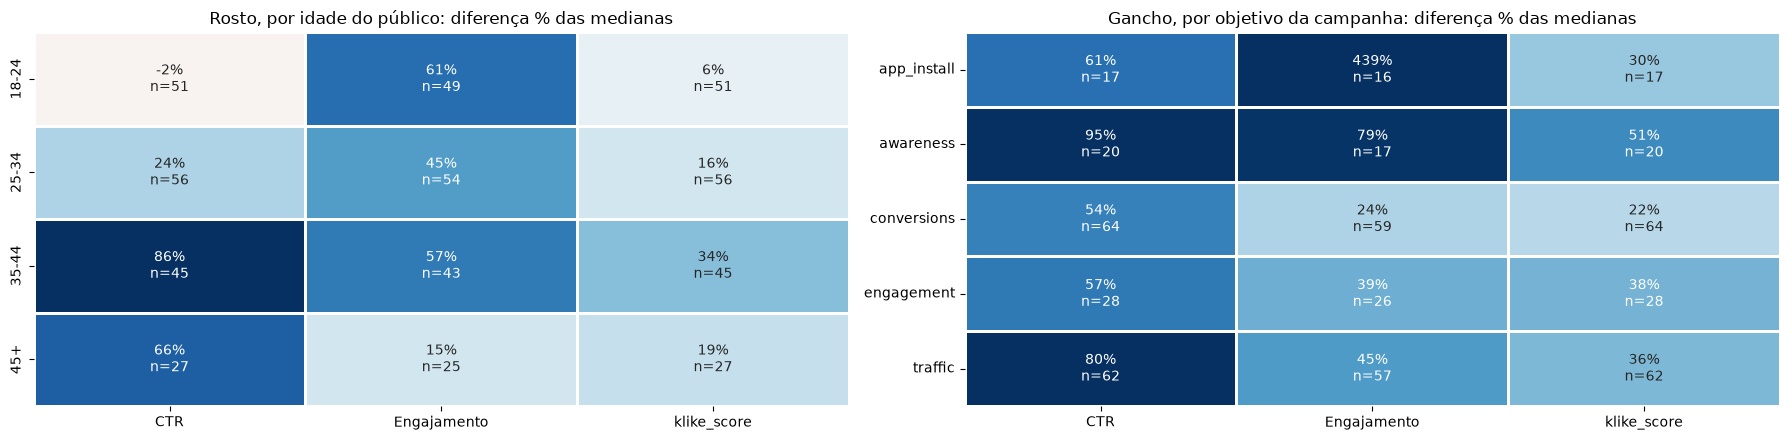

In [20]:
def diferenca_por_grupo(atributo, coluna_grupo, metricas):
    valores, contagens = {}, {}
    for nome_grupo, parte in reais.groupby(coluna_grupo):
        for metrica in metricas:
            com, sem = parte.loc[parte[atributo] == True, metrica].dropna(), parte.loc[parte[atributo] == False, metrica].dropna()
            contagens[(nome_grupo, METRICAS[metrica])] = min(len(com), len(sem))
            valores[(nome_grupo, METRICAS[metrica])] = (com.median() / sem.median() - 1) * 100
    valores, contagens = pd.Series(valores).unstack(), pd.Series(contagens).unstack()
    return valores.where(contagens >= 15), contagens


fig, eixos = plt.subplots(1, 2, figsize=(18, 4.5))
for ax, (atributo, coluna_grupo, titulo) in zip(eixos, [("has_face", "target_audience_age", "Rosto, por idade do público"),
                                                        ("has_hook", "objective", "Gancho, por objetivo da campanha")]):
    valores, contagens = diferenca_por_grupo(atributo, coluna_grupo, ["ctr", "engagement_rate", "klike_score"])
    texto_valor = valores.round(0).fillna(0).astype(int).astype(str) + "%\nn=" + contagens.astype(str)
    rotulos = texto_valor.where(valores.notna(), "n=" + contagens.astype(str))  # célula em branco: só o n
    sns.heatmap(valores, annot=rotulos, fmt="", cmap="RdBu", center=0, vmin=-80, vmax=80, cbar=False, ax=ax,
                linewidths=2, linecolor="white")
    ax.set_title(f"{titulo}: diferença % das medianas")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Pelos mapas:**

- **Rosto × idade:** no CTR, o rosto ajuda pouco de 18 a 24 anos (−2%) e muito de 35 a 44 (+86%). No engajamento é o contrário: ajuda mais de 18 a 24 (+61%) e menos acima de 45 (+15%). Como os sinais não concordam e os grupos são pequenos (25 a 56 criativos), **não há um padrão claro**: trato o rosto como um efeito geral.
- **Gancho × objetivo:** o gancho ajuda em **todos** os objetivos, no CTR (+54% a +95%) e na nota (+22% a +51%). É uma recomendação universal, não de nicho.
- Grupos pequenos dão números extremos: o +439% de engajamento em app install vem de só 16 criativos. Por isso a regra de não concluir nada com menos de 15 criativos por grupo.

## Passo 8: mantendo o resto igual, o criativo mexe em quais métricas?

A regressão do passo 6 olhou só a nota. O passo 3 olhou todas as métricas, mas sem controle: o CPC, por exemplo, depende muito da plataforma (notebook 1.3), e uma comparação simples pode confundir atributo com rede. Aqui repito a **mesma regressão, com os mesmos controles, para cada métrica**.

- As métricas têm cauda longa, então a regressão usa o **log da métrica**. O peso então se lê em %: `e^peso − 1` = quanto a métrica muda, **mantendo o resto igual**.
- O log não existe para zero: ficam de fora os criativos com 0 conversões (16) e com ROAS 0 fora de Branding (10).
- O intervalo de 95% vem do bootstrap (500 sorteios por métrica). ✓ = intervalo inteiro de um lado do zero.
- Para CPC e CPA, **menor é melhor**: um valor negativo é bom.

In [21]:
LINHAS_CRIATIVO = {"has_hook": "Gancho (hook)", "has_face": "Rosto", "has_cta": "CTA", "has_subtitle_sim": "Legenda (× não ter)",
                   "text_density_low": "Pouco texto (× médio)", "text_density_high": "Muito texto (× médio)",
                   "format_vertical": "Vertical (× quadrado)", "format_horizontal": "Horizontal (× quadrado)",
                   "video_duration_s": "+10 s de duração", "music_voice_ratio": "Só música (× só voz)"}
METRICAS_LOG = {m: n for m, n in METRICAS.items() if m != "klike_score"}

efeito_ajustado, confiavel_ajustado = {}, {}
for metrica, nome in METRICAS_LOG.items():
    valores = base_regressao[metrica]
    usar = valores.notna() & (valores > 0)
    X_m, y_m = X[usar], np.log(valores[usar])
    peso = pd.Series(LinearRegression().fit(X_m, y_m).coef_, index=X.columns)
    gerador = np.random.default_rng(42)
    sorteados = pd.DataFrame([LinearRegression().fit(X_m.iloc[s], y_m.iloc[s]).coef_
                              for s in (gerador.integers(0, len(X_m), len(X_m)) for _ in range(500))], columns=X.columns)
    baixo, alto = sorteados.quantile(0.025), sorteados.quantile(0.975)
    efeito_ajustado[nome] = ((np.exp(peso) - 1) * 100)[list(LINHAS_CRIATIVO)]
    confiavel_ajustado[nome] = ((baixo > 0) | (alto < 0))[list(LINHAS_CRIATIVO)]
    print(f"{nome}: {usar.sum()} criativos")

efeito_ajustado = pd.DataFrame(efeito_ajustado).rename(index=LINHAS_CRIATIVO)
confiavel_ajustado = pd.DataFrame(confiavel_ajustado).rename(index=LINHAS_CRIATIVO)
# a nota (passo 6), em pontos, para fechar a tabela
nota_ajustada = pesos.loc[list(LINHAS_CRIATIVO)].rename(index=LINHAS_CRIATIVO)

CTR: 343 criativos


Engajamento: 322 criativos


Retenção: 326 criativos


Taxa de conversão: 331 criativos


Conversões: 331 criativos


ROAS (sem Branding): 294 criativos


CPC (menor é melhor): 343 criativos


CPA (menor é melhor): 331 criativos


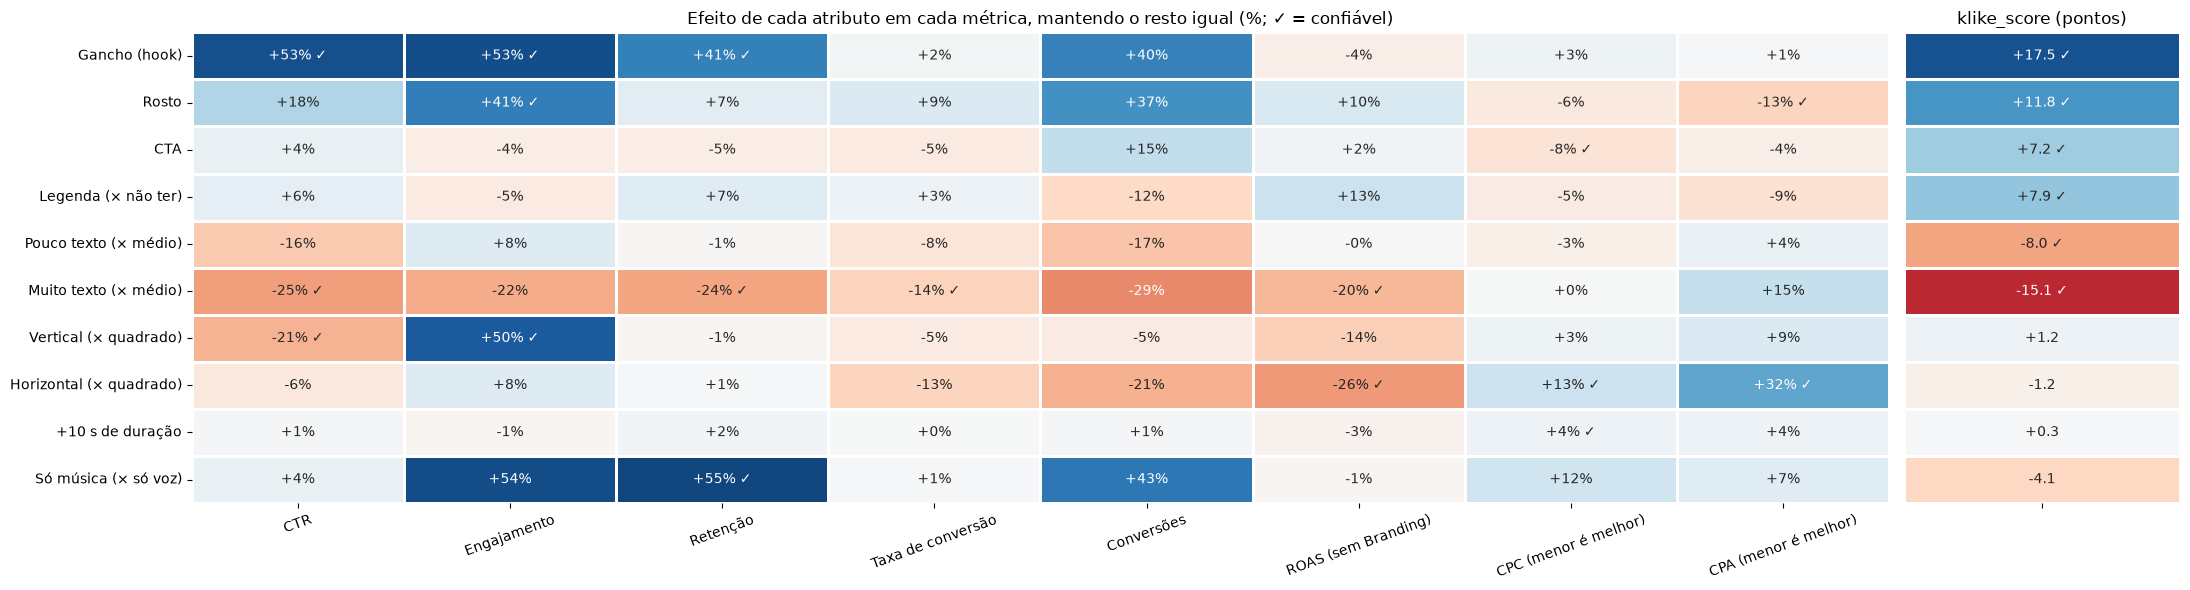

In [22]:
fig, eixos = plt.subplots(1, 2, figsize=(22, 6), gridspec_kw={"width_ratios": [8, 1.3]})
rotulos = efeito_ajustado.map(lambda v: f"{v:+.0f}%") + np.where(confiavel_ajustado, " ✓", "")
sns.heatmap(efeito_ajustado, annot=rotulos, fmt="", cmap="RdBu", center=0, vmin=-60, vmax=60, cbar=False, ax=eixos[0],
            linewidths=2, linecolor="white")
eixos[0].set_title("Efeito de cada atributo em cada métrica, mantendo o resto igual (%; ✓ = confiável)")
eixos[0].tick_params(axis="x", rotation=20)
rotulos_nota = nota_ajustada["peso (pontos)"].map(lambda v: f"{v:+.1f}") + np.where(nota_ajustada["confiável?"], " ✓", "")
sns.heatmap(nota_ajustada[["peso (pontos)"]], annot=rotulos_nota.to_frame(), fmt="", cmap="RdBu", center=0, vmin=-20, vmax=20,
            cbar=False, ax=eixos[1], linewidths=2, linecolor="white", yticklabels=False)
eixos[1].set_title("klike_score (pontos)")
eixos[1].set_xticklabels([""])
for ax in eixos:
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [23]:
# Quantos efeitos confiáveis em cada métrica (de 10 atributos)
pd.concat([confiavel_ajustado.sum(), pd.Series({"klike_score": nota_ajustada["confiável?"].sum()})]).rename("efeitos confiáveis (de 10)").to_frame().T

,CTR,Engajamento,Retenção,Taxa de conversão,Conversões,ROAS (sem Branding),CPC (menor é melhor),CPA (menor é melhor),klike_score
efeitos confiáveis (de 10),3,3,3,1,0,2,3,2,6


**Lendo o mapa (mantendo o resto igual):**

- **Começo do funil (CTR, engajamento, retenção): 9 efeitos confiáveis em 30.** O gancho sobe as três (+53% de CTR, +53% de engajamento, +41% de retenção). O rosto sobe o engajamento (+41%). O vertical engaja mais (+50%), mas tem CTR menor (−21%) que o quadrado na mesma rede. Muito texto derruba o CTR (−25%) e a retenção (−24%). Vídeo só com música prende mais (+55% de retenção), mas isso não vira nota (passo 6).
- **Fim do funil (taxa de conversão, conversões, ROAS, CPC, CPA): 8 efeitos confiáveis em 50.** O gancho, o atributo mais forte no começo, **não mexe em nada no fim** (de −4% a +2%, nenhum confiável, fora conversões, que têm intervalo largo). Os poucos efeitos no fim são:
  - **muito texto continua atrapalhando:** −14% de taxa de conversão e −20% de ROAS. É o único atributo que pesa no funil inteiro;
  - **formato horizontal sai mais caro:** CPA +32%, CPC +13% e ROAS −26% (contra quadrado, na mesma rede);
  - **rosto barateia a conversão** (CPA −13%), **CTA barateia o clique** (CPC −8%) e cada 10 s a mais encarecem o clique em 4%: efeitos pequenos, que podem ser acaso (ver abaixo).
- **Muitas comparações:** são 80 (10 atributos × 8 métricas); umas 4 sairiam "confiáveis" por sorte. Por isso confio mais nos efeitos que se repetem: o gancho no começo do funil, o muito texto em todo o funil e o horizontal nas três métricas de custo.
- **Quem move o fim do funil é o público:** na comparação simples (passo 3), o retargeting tem CPA 44% menor, ROAS 66% maior e quase 4 vezes mais conversões. O criativo decide se a pessoa para e clica; quem converte depende de quem é a pessoa e da oferta.

## Passo 9: a "boa métrica" depende do objetivo da campanha

Uma campanha de awareness quer ser vista até o fim; uma de traffic quer cliques; uma de conversions quer vender barato. Julgar todas pelo CTR seria injusto. Para cada objetivo, escolho a **métrica principal** (tabela do notebook 1.1) e meço o efeito de cada atributo nela, só dentro daquele objetivo (diferença das medianas com intervalo de 95%; células com menos de 15 criativos ficam em branco).

| Objetivo | Métrica principal | Melhor quando |
|---|---|---|
| awareness | retenção | maior |
| engagement | engajamento | maior |
| traffic | CTR | maior |
| conversions | CPA | menor |
| app_install | CPA (custo por instalação) | menor |

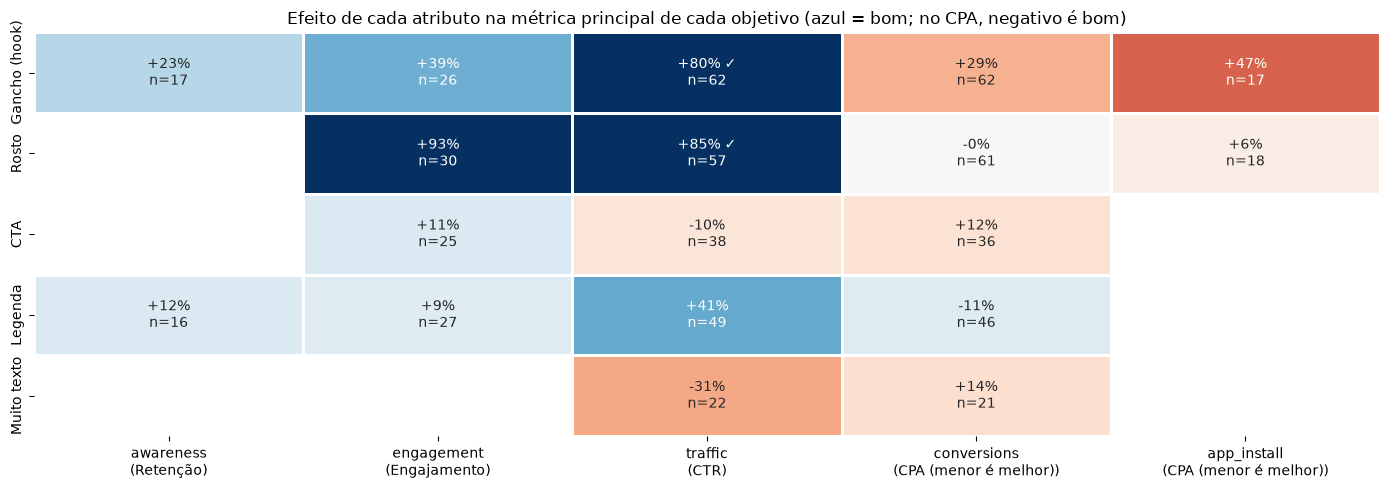

In [24]:
METRICA_DO_OBJETIVO = {"awareness": "retencao", "engagement": "engagement_rate", "traffic": "ctr",
                       "conversions": "cpa", "app_install": "cpa"}
ATRIBUTOS_OBJETIVO = dict(list(ATRIBUTOS_SIM_NAO.items())[:4])
ATRIBUTOS_OBJETIVO["Muito texto"] = reais["text_density"] == "high"

linhas = []
for objetivo, metrica in METRICA_DO_OBJETIVO.items():
    parte = reais["objective"] == objetivo
    for atributo, tem in ATRIBUTOS_OBJETIVO.items():
        com, sem = reais.loc[parte & (tem == True), metrica], reais.loc[parte & (tem == False), metrica]
        resultado = comparar(com, sem)
        linhas.append({"objetivo": f"{objetivo}\n({METRICAS[metrica]})", "atributo": atributo, **resultado,
                       "n menor grupo": min(resultado["n com"], resultado["n sem"])})
por_objetivo = pd.DataFrame(linhas)

valores = por_objetivo.pivot(index="atributo", columns="objetivo", values="diferença (%)").loc[list(ATRIBUTOS_OBJETIVO)]
n = por_objetivo.pivot(index="atributo", columns="objetivo", values="n menor grupo").loc[list(ATRIBUTOS_OBJETIVO)]
confiavel = por_objetivo.pivot(index="atributo", columns="objetivo", values="confiável?").loc[list(ATRIBUTOS_OBJETIVO)]
ordem_colunas = [c for o in METRICA_DO_OBJETIVO for c in valores.columns if c.startswith(o)]
valores, n, confiavel = valores[ordem_colunas], n[ordem_colunas], confiavel[ordem_colunas]
# CPA: menor é melhor; troco o sinal da cor para azul continuar sendo "bom"
cor = valores.copy()
cor[[c for c in ordem_colunas if "CPA" in c]] *= -1
rotulos = valores.map(lambda v: f"{v:+.0f}%") + np.where(confiavel, " ✓", "") + "\nn=" + n.astype(int).astype(str)
rotulos = rotulos.where(n >= 15, "n=" + n.astype(int).astype(str))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(cor.where(n >= 15), annot=rotulos, fmt="", cmap="RdBu", center=0, vmin=-80, vmax=80, cbar=False, ax=ax,
            linewidths=2, linecolor="white")
ax.set_title("Efeito de cada atributo na métrica principal de cada objetivo (azul = bom; no CPA, negativo é bom)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Pelo mapa por objetivo:**

- **Traffic (CTR):** gancho (+80%) e rosto (+85%) são confiáveis. É onde o criativo mais aparece, porque a métrica do objetivo é o clique.
- **Awareness (retenção):** muito texto derruba a retenção em 32%, o único efeito confiável. Os outros atributos sobem a retenção (+12% a +42%), mas com só 36 criativos o intervalo cruza o zero.
- **Engagement (engajamento):** o rosto quase dobra o engajamento (+93%), mas o intervalo encosta no zero (−2% a +195%). Indício.
- **Conversions e app install (CPA):** nenhum atributo muda o CPA de forma confiável. Confirma o passo 8: o custo por conversão depende mais do público e da oferta do que do vídeo.
- **Limite:** cada objetivo tem de 36 a 129 criativos, e vários grupos ficam abaixo de 15 (por exemplo, muito texto em app install, com 6). Os resultados são direção, não estimativa precisa.

## Resposta à pergunta 1.2

Analisei **nove métricas**, do começo ao fim do funil: CTR, engajamento, retenção, taxa de conversão, conversões, ROAS, CPC, CPA e a nota `klike_score` (o alvo da Parte 2).

**Na nota (mantendo o resto igual):**

- **Gancho nos 3 primeiros segundos é o atributo mais forte:** +17,5 pontos (intervalo de 15,7 a 19,1). Funciona em todas as plataformas e objetivos.
- **Rosto humano é o segundo:** +11,8 pontos.
- **Legenda (+7,9) e CTA (+7,2)** também somam.
- **Texto na tela tem um ponto ótimo no meio:** muito texto tira 15,1 pontos; pouco texto tira 8,0.
- **Formato, duração e música/voz** não mudam a nota de forma clara.

**Em cada etapa do funil (mantendo o resto igual, passo 8):**

| Atributo | Ver e interagir (CTR, engajamento, retenção) | Converter e vender (conversão, ROAS, CPC, CPA) |
|---|---|---|
| Gancho | **sobe tudo:** CTR +53%, engajamento +53%, retenção +41% | nada |
| Rosto | engajamento +41% | CPA −13% (indício) |
| Muito texto | **derruba:** CTR −25%, retenção −24% | **derruba:** taxa de conversão −14%, ROAS −20% |
| Formato horizontal (× quadrado) | nada | **mais caro:** CPA +32%, CPC +13%, ROAS −26% |
| Formato vertical (× quadrado) | CTR −21%, engajamento +50% | nada |
| CTA | nada | CPC −8% (indício) |
| Duração | nada | CPC +4% a cada 10 s |
| Música/voz | só música prende mais (retenção +55%) | nada |
| Legenda | nada | nada |

- **O criativo age principalmente no começo do funil:** 9 efeitos confiáveis em 30 no começo, contra 8 em 50 no fim. **Vender depende mais do público e da oferta:** o retargeting tem CPA 44% menor e ROAS 66% maior.
- **Exceções no fim do funil:** muito texto atrapalha do clique à venda, e o formato horizontal sai mais caro por conversão.
- **A boa métrica depende do objetivo (passo 9):** em traffic, gancho e rosto sobem o CTR em cerca de 80%; em awareness, muito texto derruba a retenção em 32%; em conversions e app install, nenhum atributo muda o CPA de forma confiável.
- **Retargeting** sobe muito o CTR (+70%), mas é efeito do público: compare criativos dentro do mesmo tipo de público.

## O que isso significa para a Parte 2

- **Há bastante sinal antes de postar:** uma regressão só com atributos e contexto explica 74% da variação da nota no treino. A Parte 2 confirma isso no teste, uma única vez.
- **Colunas mais promissoras:** gancho, rosto, densidade de texto (como categoria, porque o meio é melhor que os extremos), CTA, legenda e retargeting.
- **Não usar CTR, retenção, engajamento, CPA etc. como colunas** de um modelo "antes de postar": a nota anda junto com elas (0,56 com o CTR), mas elas só existem depois. Um modelo "completo", com elas, serve só para comparar.
- **Os indicadores de faltante** (`_faltava`) entram como colunas candidatas: o modelo decide se o fato de faltar ajuda.



## Limites desta análise

- **Dados simulados:** a retenção que não cai com a duração parece uma simplificação.
- **Dados observados, não experimento:** os efeitos são associações. Um teste A/B seria a prova.
- **Muitas comparações (45 diferenças no passo 3):** algumas parecerão confiáveis por sorte. Por isso só destaco o que se repete em várias métricas ou grupos.
- **CTR cortado em 0,15:** os melhores vídeos batem no teto, então o efeito do gancho no CTR está subestimado.
- **Regressão no log (passo 8):** criativos com 0 conversões (16) ou ROAS 0 fora de Branding (10) ficam de fora dessas métricas, porque o log de zero não existe.
- **Atributos sim/não:** "tem gancho" não diz se o gancho é bom. Medir a qualidade do criativo é justamente o papel do Klike.